<a href="https://colab.research.google.com/github/VictorGMSS/Machine_Learning_clasificacao_validando_modelos_e_metricas_de_avaliacao/blob/main/metricas_de_avaliacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color='SteelBlue'>**Classificação: Validação de modelos e métricas de avaliação**</h1>

### Projeto

Uma empresa de empréstimo de automóveis está passando por uma situação complicada, com alta demanda para uma frota reduzida de veículos e alto número de inadimplentes, trazendo um prejuízo grande para a empresa.

Nós fomos contratados para buscar melhorias na identificação de inadimplentes. A análise dos clientes atualmente é feita de forma manual, cliente por cliente, tomando muito tempo e ainda assim a detecção de inadimplentes é muito imprecisa.

Nossa tarefa é utilizar os dados fornecidos pela empresa para **classificar** os clientes em adimplentes e inadimplentes.

## <font color='SteelBlue'>Importando bibliotecas</h1>

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_auc_score
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.metrics import average_precision_score
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_validate, KFold, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import NearMiss
from imblearn.pipeline import Pipeline as imbpipeline

## <font color='SteelBlue'>Classificando dados</h1>

### Criando um modelo inicial

In [ ]:
dados = pd.read_csv('https://raw.githubusercontent.com/VictorGMSS/Machine_Learning_clasificacao_validando_modelos_e_metricas_de_avalia-o/refs/heads/main/emp_automovel.csv')

In [ ]:
dados

,receita_cliente,anuidade_emprestimo,anos_casa_propria,telefone_trab,avaliacao_cidade,score_1,score_2,score_3,score_social,troca_telefone,inadimplente
0,12600.000000,3569.400000,12.157324,1,2.0,0.057153,0.527227,0.513171,0.117428,2545.000000,0
1,9000.000000,2722.188351,7.000000,0,2.0,0.657661,0.285898,0.614414,0.222700,495.000000,0
2,15750.000000,4477.500000,12.000000,0,2.0,0.501213,0.695423,0.513171,0.117428,1212.000000,0
3,9000.000000,1309.050000,12.157324,0,3.0,0.501213,0.155973,0.513171,0.117428,515.000000,0
4,7650.000000,1125.000000,12.157324,0,2.0,0.294328,0.152076,0.513171,0.117428,162.000000,0
...,...,...,...,...,...,...,...,...,...,...,...
54020,16855.246324,675.000000,12.157324,1,2.0,0.501213,0.180635,0.513171,0.082500,0.000000,1
54021,11250.000000,675.000000,14.000000,0,3.0,0.409620,0.606002,0.513171,0.117428,466.000000,1
54022,13500.000000,900.000000,64.000000,0,2.0,0.162632,0.525412,0.513171,0.117428,962.106056,1
54023,11250.000000,2371.500000,12.157324,0,3.0,0.501213,0.664027,0.513171,0.117428,482.000000,1


In [ ]:
#X recebe todas as colunas menos a variavel alvo, enquanto Y é o inverso
x = dados.drop('inadimplente', axis=1)
y = dados['inadimplente']

In [ ]:
modelo = DecisionTreeClassifier()
modelo.fit(x, y)
modelo.score(x, y)

1.0

In [ ]:
#Acurácia feita da forma errada, pois testa com os mesmos dados de treinamento (gabarito)
print(f'Acurácia: {modelo.score(x,y)}')

Acurácia: 1.0


### Validando o modelo

Avaliar os modelo com base nos mesmos dados usados no treinamento não é interessante. É preciso que a avaliação seja feita em dados independentes.

Avaliar o modelo nos próprios dados de treinamento seria o análogo a entregar uma prova com as questões e o gabarito para uma pessoa e no momento de avaliá-la novamente, entregar uma prova com as mesmas questões e alternativas. É esperado que essa pessoa se sairá bem por já ter visto as respostas e ter decorado o resultado. Isso é diferente de ter aprendido a matéria a partir daquela prova e depois fazer uma prova com conteúdo parecido e ter um resultado positivo.

No intuito de checar a generalização de um modelo, devemos separar o conjunto de dados em 3 partes: dados de treinamento, validação e teste.

- o conjunto de treinamento é utilizado para treinar os modelos. Os modelos vão entender o padrão dos dados a partir desse conjunto de dados.

- o conjunto de validação é utilizado para avaliar o desempenho de diferentes modelos, com dados novos que não foram usados no treinamento do modelo.

- o conjunto de teste fica separado dos demais desde o momento inicial para simular os dados do mundo real. Ele não é utilizado em nenhum momento no treinamento e nem na validação, servindo como uma estimativa da capacidade do modelo escolhido de generalizar e prever novos dados.

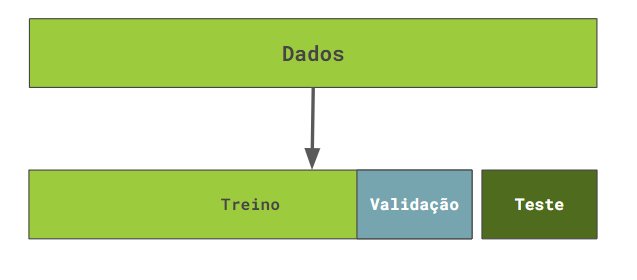

In [ ]:
x, x_teste, y, y_teste = train_test_split(x, y, test_size = 0.15, stratify = y, random_state = 5)
x_treino, x_val, y_treino, y_val = train_test_split(x, y, stratify = y, random_state = 5)

In [ ]:
modelo = DecisionTreeClassifier(max_depth = 10)
modelo.fit(x_treino, y_treino)
print(f'Acurácia de treino: {modelo.score(x_treino, y_treino)}')
print(f'Acurácia de validação: {modelo.score(x_val, y_val)}')

Acurácia de treino: 0.9205865272938444
Acurácia de validação: 0.9063670411985019


###  Avaliando o modelo

In [ ]:
y_previsto = modelo.predict(x_val)
matriz_confusao = confusion_matrix(y_val, y_previsto)
print(matriz_confusao)

[[10362   117]
 [  958    44]]


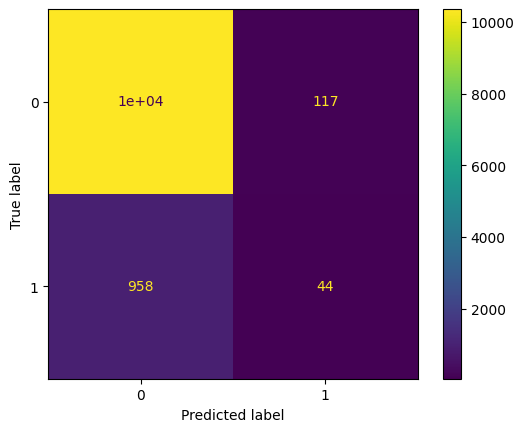

In [ ]:
visualizacao = ConfusionMatrixDisplay(confusion_matrix = matriz_confusao)
visualizacao.plot();

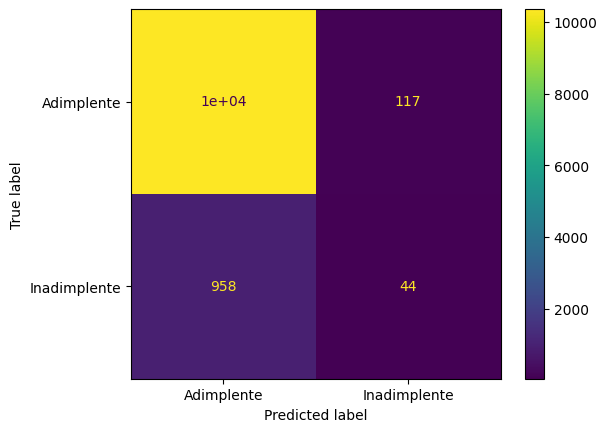

In [ ]:
visualizacao = ConfusionMatrixDisplay(confusion_matrix = matriz_confusao, display_labels = ['Adimplente', 'Inadimplente'])
visualizacao.plot();

## <font color='SteelBlue'>Métricas de avaliação</h1>

### Acurácia, precisão e recall

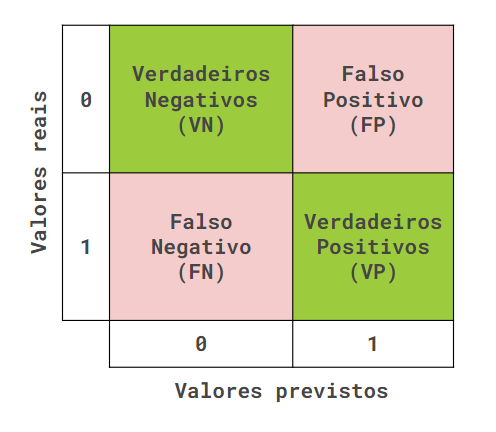

In [ ]:
print(f'Acurácia: {accuracy_score(y_val, y_previsto)}')

Acurácia: 0.9063670411985019


In [ ]:
print(f'Precisão: {precision_score(y_val, y_previsto)}')
print(f'Recall: {recall_score(y_val, y_previsto)}')

Precisão: 0.2732919254658385
Recall: 0.043912175648702596


In [ ]:
print(f'F1-Score: {f1_score(y_val, y_previsto)}')

F1-Score: 0.07566638005159071


### Curva ROC

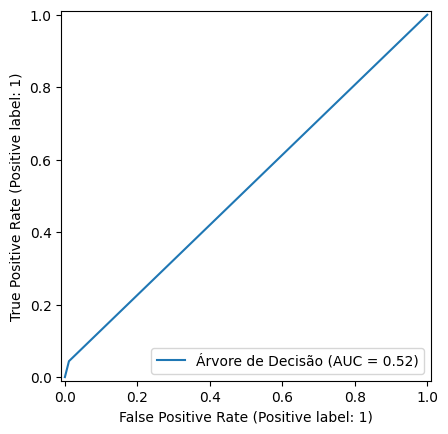

In [ ]:
RocCurveDisplay.from_predictions(y_val, y_previsto, name = 'Árvore de Decisão');

In [ ]:
print(f'AUC: {roc_auc_score(y_val, y_previsto)}')

AUC: 0.5163734940654049


### Curva de precisão x recall

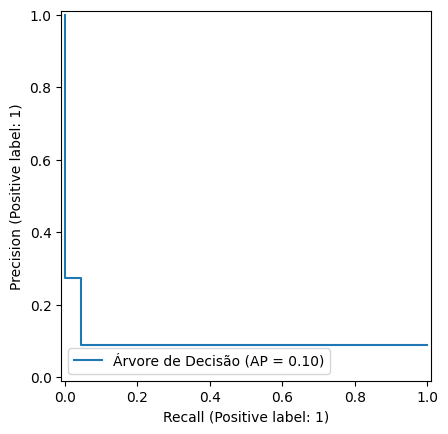

In [ ]:
PrecisionRecallDisplay.from_predictions(y_val, y_previsto, name = 'Árvore de Decisão');

In [ ]:
print(f'AP: {average_precision_score(y_val, y_previsto)}')

AP: 0.09544305190125149


### Relatório de métricas

In [ ]:
print(classification_report(y_val, y_previsto))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     10479
           1       0.27      0.04      0.08      1002

    accuracy                           0.91     11481
   macro avg       0.59      0.52      0.51     11481
weighted avg       0.86      0.91      0.87     11481



## <font color='SteelBlue'>Validação cruzada</h1>

### Usando o KFold

A validação do modelo de classificação a partir da separação dos dados em conjunto de treino e validação faz com que o resultado seja muito dependente dessa divisão dos dados e pode ser que, de forma aleatória, o padrão dos dados de validação sejam diferentes do padrão dos dados de treinamento, levando a sorte de ter um resultado muito melhor do que a realidade ou o azar de um resultado muito pior do que a realidade.

Levando isso em consideração, é possível utilizar a **validação cruzada**, uma estratégia mais consistente e bem mais utilizada nos projetos de machine learning.

Na validação cruzada, ao invés de separarmos os dados em apenas treino e validação uma única vez, dividimos os dados em várias partes de mesmo tamanho. Em cada uma dessas divisões, será utilizada uma parte para validação e todas as outras para treinamento e o processo se repete até que todas as partes sejam utilizadas para validação e o restante para treinamento.

Será gerado um modelo para cada uma dessas divisões e a avaliação de desempenho será feita tirando a média da métrica de cada modelo. Isso faz com que a dependência da separação dos dados seja eliminada, já que há uma variação maior da escolha dos dados e é retirada uma média.

Geralmente são utilizadas 5 ou 10 partes, mais do que isso não é tão necessário porque necessita de um processamento maior e valores menores já mitiga o problema da escolha dos dados.

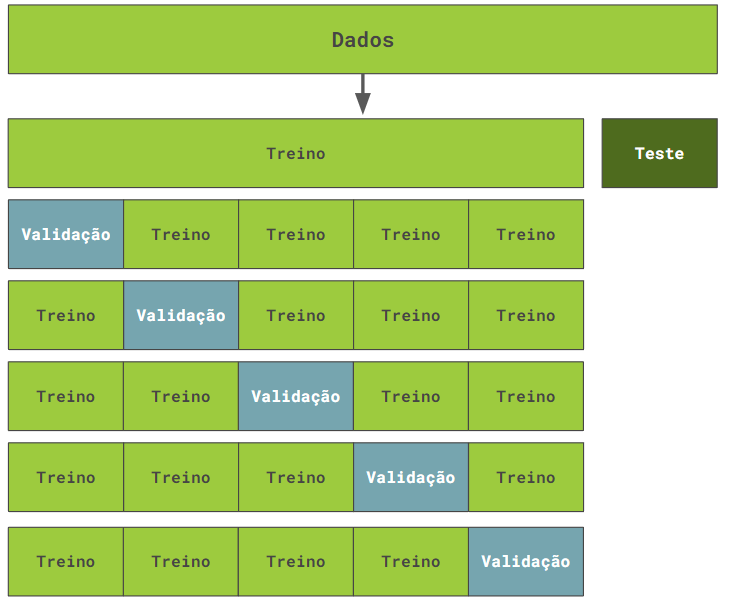

In [ ]:
modelo = DecisionTreeClassifier(max_depth = 10)
kf = KFold(n_splits = 5, shuffle =True, random_state = 5)
cv_resultados = cross_validate(modelo, x, y, cv = kf)
cv_resultados

{'fit_time': array([0.25032663, 0.24988437, 0.24423194, 0.25489879, 0.24593997]),
 'score_time': array([0.00372934, 0.00344324, 0.00333619, 0.00430655, 0.00359631]),
 'test_score': array([0.91290147, 0.90712108, 0.90733885, 0.91376307, 0.89949913])}

In [ ]:
media = cv_resultados['test_score'].mean()
desvio_padrao = cv_resultados['test_score'].std()
print(f'Intervalo de confiança: [{media - 2*desvio_padrao}, {min(media + 2*desvio_padrao, 1)}] media: {media}, desvio padrão: {desvio_padrao}')

Intervalo de confiança: [0.8979018430397813, 0.9183475950495138] media: 0.9081247190446475, desvio padrão: 0.005111438002433154


### Validação cruzada com recall

In [ ]:
def intervalo_conf(resultados):
  media = resultados['test_score'].mean()
  desvio_padrao = resultados['test_score'].std()
  print(f'Intervalo de confiança: [{media - 2*desvio_padrao}, {min(media + 2*desvio_padrao, 1)}] media: {media}, desvio padrão: {desvio_padrao}')

In [ ]:
modelo = DecisionTreeClassifier(max_depth = 10)
kf = KFold(n_splits = 5, shuffle =True, random_state = 5)
cv_resultados = cross_validate(modelo, x, y, cv = kf, scoring = 'recall')
cv_resultados

{'fit_time': array([0.35855913, 0.25555778, 0.25255704, 0.25585008, 0.27720332]),
 'score_time': array([0.00998306, 0.0061748 , 0.0062983 , 0.00827098, 0.0059545 ]),
 'test_score': array([0.02906209, 0.01980198, 0.01845018, 0.01305483, 0.02427746])}

In [ ]:
intervalo_conf(cv_resultados)

Intervalo de confiança: [0.010093200817495224, 0.03176541471079737] media: 0.0209293077641463, desvio padrão: 0.0054180534733255376


### Estratificando os dados

In [ ]:
dados['inadimplente'].value_counts(normalize = True)

,proportion
inadimplente,
0,0.912707
1,0.087293


In [ ]:
modelo = DecisionTreeClassifier(max_depth = 10)
skf = StratifiedKFold(n_splits = 5, shuffle =True, random_state = 5)
cv_resultados = cross_validate(modelo, x, y, cv = skf, scoring = 'recall')

In [ ]:
intervalo_conf(cv_resultados)

Intervalo de confiança: [0.021301501953200117, 0.03407379264426377] media: 0.027687647298731945, desvio padrão: 0.003193072672765913


## <font color='SteelBlue'>Balanceamento de dados</h1>

### Oversampling

In [ ]:
oversample = SMOTE()
x_balanceado, y_balanceado = oversample.fit_resample(x, y)

In [ ]:
y_balanceado.value_counts(normalize=True)

,proportion
inadimplente,
0,0.5
1,0.5


In [ ]:
modelo = DecisionTreeClassifier(max_depth = 10)
skf = StratifiedKFold(n_splits = 5, shuffle =True, random_state = 5)
cv_resultados = cross_validate(modelo, x_balanceado, y_balanceado, cv = skf, scoring = 'recall')

In [ ]:
intervalo_conf(cv_resultados)

Intervalo de confiança: [0.7114931643346031, 0.7656501196740938] media: 0.7385716420043484, desvio padrão: 0.013539238834872692


### Pipeline para validação

In [ ]:
modelo = DecisionTreeClassifier(max_depth=10)
pipeline = imbpipeline(steps = [('oversample', SMOTE()), ('arvore', modelo)])
skf = StratifiedKFold(n_splits = 5, shuffle =True, random_state = 5)
cv_resultados = cross_validate(pipeline, x, y, cv = skf, scoring = 'recall')

In [ ]:
intervalo_conf(cv_resultados)

Intervalo de confiança: [0.22468806279213444, 0.30910666387434543] media: 0.26689736333323993, desvio padrão: 0.021104650270552756


### Undersampling

In [ ]:
modelo = DecisionTreeClassifier(max_depth=10)
pipeline = imbpipeline(steps = [('undersample', NearMiss(version = 3)), ('arvore', modelo)])
skf = StratifiedKFold(n_splits = 5, shuffle =True, random_state = 5)
cv_resultados = cross_validate(pipeline, x, y, cv = skf, scoring = 'recall')

In [ ]:
intervalo_conf(cv_resultados)

Intervalo de confiança: [0.6232031965778552, 0.696810128411793] media: 0.6600066624948241, desvio padrão: 0.018401732958484473


### Testando o modelo

              precision    recall  f1-score   support

           0       0.94      0.48      0.64      7397
           1       0.11      0.70      0.20       707

    accuracy                           0.50      8104
   macro avg       0.53      0.59      0.42      8104
weighted avg       0.87      0.50      0.60      8104



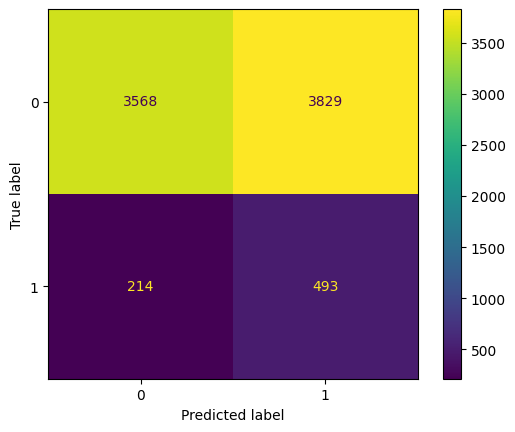

In [ ]:
undersample = NearMiss(version = 3)
x_balanceado, y_balanceado = undersample.fit_resample(x, y)

modelo = DecisionTreeClassifier(max_depth=10)
modelo.fit(x_balanceado, y_balanceado)
y_previsto = modelo.predict(x_teste)

print(classification_report(y_teste, y_previsto))
ConfusionMatrixDisplay.from_predictions(y_teste, y_previsto);